<a href="https://colab.research.google.com/github/AdelineKwakye/walmart-huricane-project/blob/main/notebooks/scratch/Adeline_Kwakye_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# what needs to be done:

  # handle duplicates

  # convert unit price from text -> real number

  # decide on whether negatives values are kept ( yes because they indicate returns / refunds )

  # parse timestamp to turn it into date time

  # clean store_id


# import data
import pandas as pd
walmart_transactions = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/walmart_transactions.csv'
store_locations = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/store_locations.csv'
distribution_centers = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/distribution_centers.csv'
df_transactions = pd.read_csv(walmart_transactions)
df_store = pd.read_csv(store_locations)
df_distribution_centers = pd.read_csv(distribution_centers)

print("Store data\n")
print(df_store.head())
print("transactions sample\n")
print(df_transactions.head(10))
print("distribution centers\n")
display(df_distribution_centers)



Store data

  store_id                             store_name          city    state  \
0   FL-239            Walmart Supercenter Orlando       Orlando       FL   
1   FL-105              Walmart Supercenter Tampa         Tampa       FL   
2   FL-330              Walmart Supercenter Miami         Miami       FL   
3   FL-412       Walmart Supercenter Jacksonville  Jacksonville       FL   
4   FL-287  Walmart Neighborhood Market Kissimmee     Kissimmee  Florida   

   zip_code  latitude  longitude   region  
0     32801   28.5383   -81.3792  Central  
1     33602   27.9506   -82.4572     West  
2     33101   25.7617   -80.1918    South  
3     32099   30.3322   -81.6557    North  
4     34741   28.2920   -81.4076  Central  
transactions sample

  transaction_id store_id            timestamp            sku  \
0      TXN012636   FL-710  2024-09-24T09:48:13     PNUTBTR-16   
1      TXN000759   fl-412  2024-09-13 20:30:20      CNSOUP-01   
2      TXN003338   FL-105  2024-09-17 10:06:00  TOI

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


In [3]:
# setting up decision log
# used same formating from decision log in previous lab
DECISIONS = []

def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

def show_log():
    return pd.DataFrame(DECISIONS)

raw_rows = len(df_transactions)
print('starting with', raw_rows, 'rows')

starting with 25562 rows


In [4]:
# handle duplicate function

def handle_duplicates (df_name):
  before_len = len(df_name) # length before
  print("Length before cleaning duplicates: ", before_len)
  removed = df_name.duplicated().sum() # duplicated rows to be removed
  clean_dup = df_name.drop_duplicates().copy() # drop duplicates
  after_len = len(clean_dup) # length after
  print( "Length after cleaning duplicates: ", after_len)
  log('duplicates', 'dropped exact duplicate rows', removed) # log
  return clean_dup

df_clean = handle_duplicates(df_transactions)
show_log()

Length before cleaning duplicates:  25562
Length after cleaning duplicates:  25532
[duplicates] dropped exact duplicate rows (30 row(s))


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30


In [5]:
# handle unit price
def clean_unit_price(df_name):
    before_len = len(df_name)
    print("Length before cleaning: ", before_len)
    clean_df = df_name.copy()


    # Strip '$' and convert directly to float
    clean_df['unit_price'] = (
        clean_df['unit_price']
        .astype(str)
        .str.replace('$', '', regex=False)
        .str.strip()
        .astype(float)
    )

    assert clean_df['unit_price'].dtype == float # confirm that it's a float

    after_len = len(clean_df)
    print("Length after cleaning: ", after_len)
    log('unit price', 'stripped $ and converted to float', len(clean_df))
    return clean_df

df_clean = clean_unit_price(df_clean)
show_log()

Length before cleaning:  25532
Length after cleaning:  25532
[unit price] stripped $ and converted to float (25532 row(s))


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532


In [6]:
# handle negative values
def handle_negative_values(df_name):
  # keeping negative values since representative of refunds/ returns
  # this function will just ensure that quantity is a numeric value

  before_len = len(df_name)
  print("Length before cleaning: ", before_len)
  clean_df = df_name.copy()

  clean_df['quantity'] = pd.to_numeric(clean_df['quantity'], errors="coerce") # convert to numeric

  # keep track of negative values
  negative_values = (clean_df['quantity'] < 0 ).sum()
  print("Number of negative values: ", negative_values)

  after_len = len(clean_df)
  print("Length after cleaning: ", after_len)

  log('negative quantity', 'decided to keep all of the negative quantities since it could be indicative of refunds/returns', 0)
  return clean_df

df_clean = handle_negative_values(df_clean)
show_log()


Length before cleaning:  25532
Number of negative values:  130
Length after cleaning:  25532
[negative quantity] decided to keep all of the negative quantities since it could be indicative of refunds/returns (0 row(s))


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0


In [7]:
# cleaning store_id
def clean_store_id(df_name, table_name):
    before_len = len(df_name)
    print(f"Length before cleaning {table_name}: ", before_len)
    clean_df = df_name.copy()

    # standardize the store id to start with FL-###
    # using format that was done in previous lab/studio
    clean_df['store_id'] = (
        clean_df['store_id']
        .astype(str)
        .str.upper()
        .str.strip()
        .str.replace(r'[^A-Z0-9]', '', regex=True)
        .apply(lambda s: f'{s[:2]}-{s[2:]}')
    )

    after_len = len(clean_df)
    print(f"Length after cleaning {table_name}: ", after_len)

    log(
        f'store_id ({table_name})',
        f'standardized formatting of store_id to follow FL-### in {table_name}',
        len(clean_df),
    )
    return clean_df

df_clean = clean_store_id(df_clean, table_name='transactions') # standardize store id from transactions
df_clean_store = clean_store_id(df_store, table_name='stores') # standardize store id from stores
show_log()

Length before cleaning transactions:  25532
Length after cleaning transactions:  25532
[store_id (transactions)] standardized formatting of store_id to follow FL-### in transactions (25532 row(s))
Length before cleaning stores:  14
Length after cleaning stores:  14
[store_id (stores)] standardized formatting of store_id to follow FL-### in stores (14 row(s))


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14


In [8]:
# view list of clean store names
print("df_clean store_id samples:\n", df_clean['store_id'].head(3))
print("df_clean_store store_id samples:\n", df_clean_store['store_id'].head(3))

# confirm that the store names match
print(df_clean['store_id'].isin(df_clean_store['store_id']).all())
print(df_clean_store['store_id'].isin(df_clean['store_id']).all())

# view the updated decisions log
show_log()

df_clean store_id samples:
 0    FL-710
1    FL-412
2    FL-105
Name: store_id, dtype: object
df_clean_store store_id samples:
 0    FL-239
1    FL-105
2    FL-330
Name: store_id, dtype: object
True
True


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14


In [9]:
# handle timestamps

def clean_timestamps(df_name):
  before_len = len(df_name)
  print("Length before cleaning: ", before_len)
  clean_df = df_name.copy()

  # standardize the timestamp column so it uses space as a separator and a T

  clean_df['timestamp'] = (
      clean_df['timestamp']
      .astype(str)
      .str.strip()
      .str.replace('T', ' ', regex=False)
  )
  # convert to datetime

  clean_df['timestamp'] = pd.to_datetime(clean_df['timestamp'], format='mixed', errors='coerce')

  null_count = clean_df['timestamp'].isnull().sum()
  print("Number of null values: ", null_count)
  # drop na
  clean_df = clean_df.dropna(subset=['timestamp']).copy()

  # create normalized date column
  clean_df['date'] = clean_df['timestamp'].dt.normalize()

  after_len = len(clean_df)
  print("Length after cleaning, ", after_len)
  log('timestamp', 'standardized the separator, converted to be datetime, droped na values, and created a normalized date column ', null_count)
  return clean_df

print('nulls in df_clean: ', df_clean['timestamp'].isnull().sum())

df_clean = clean_timestamps(df_clean)
print('nulls in df_clean: ', df_clean['timestamp'].isnull().sum())
show_log()


nulls in df_clean:  884
Length before cleaning:  25532
Number of null values:  884
Length after cleaning,  24648
[timestamp] standardized the separator, converted to be datetime, droped na values, and created a normalized date column  (884 row(s))
nulls in df_clean:  0


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884


In [10]:
# Check remaining nulls across all columns
print("Remaining nulls per column:")
print(df_clean.isnull().sum())

Remaining nulls per column:
transaction_id    0
store_id          0
timestamp         0
sku               0
product_name      0
category          0
quantity          0
unit_price        0
date              0
dtype: int64


In [11]:
def profile(df, name='dataset'):
    print(f'=== {name} ===')
    print(f'{len(df):,} rows x {len(df.columns)} columns')
    print()
    summary = pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'nulls': df.isnull().sum(),
        'null_pct': (100 * df.isnull().mean()).round(1),
        'distinct': df.nunique(),
    })
    print(summary)
    print()
    print('exact duplicate rows:', df.duplicated().sum())
    return summary


    # Final post-cleaning health check
profile(df_clean, name='Cleaned Transactions (df_clean)')

=== Cleaned Transactions (df_clean) ===
24,648 rows x 9 columns

                         dtype  nulls  null_pct  distinct
transaction_id          object      0       0.0     24648
store_id                object      0       0.0        12
timestamp       datetime64[ns]      0       0.0     23417
sku                     object      0       0.0        45
product_name            object      0       0.0        63
category                object      0       0.0        37
quantity                 int64      0       0.0        11
unit_price             float64      0       0.0      1667
date            datetime64[ns]      0       0.0        30

exact duplicate rows: 0


,dtype,nulls,null_pct,distinct
transaction_id,object,0,0.0,24648
store_id,object,0,0.0,12
timestamp,datetime64[ns],0,0.0,23417
sku,object,0,0.0,45
product_name,object,0,0.0,63
category,object,0,0.0,37
quantity,int64,0,0.0,11
unit_price,float64,0,0.0,1667
date,datetime64[ns],0,0.0,30


In [12]:
# clean distribution center csv
  # unnecessary ~ in surge_capacity column
  # Nan value in cost per shipment


print(df_distribution_centers.info())
print(df_distribution_centers.isnull().sum())

def clean_distribution_center(df_name):
  before_len = len(df_name)
  print("Length before cleaning: ", before_len)
  clean_df = df_name.copy()
  clean_df['surge_capacity'] = clean_df['surge_capacity'].str.strip().str.replace('~', '', regex=False)
  clean_df['surge_capacity'] = pd.to_numeric(clean_df['surge_capacity'], errors='coerce')

  # Count missing shipping costs
  missing_costs = clean_df['cost_per_shipment'].isna().sum()
  print("Missing shipping costs:", missing_costs)

  # Check for missing shipping costs
  missing_costs = clean_df['cost_per_shipment'].isna().sum()
  print("Missing shipping costs:", missing_costs)

  after_len = len(clean_df)
  ## log
  log('surge capacity', 'striped white spaces, got rid of ~, and converted type to be numeric', after_len)
  log('distribution center missing values', 'kept missing value because there is no reliable information to determine correct value', 0)

  return clean_df

clean_distribution_center_df = clean_distribution_center(df_distribution_centers)
show_log()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   dc_id                   5 non-null      object 
 1   dc_name                 5 non-null      object 
 2   city                    5 non-null      object 
 3   state                   5 non-null      object 
 4   avg_daily_shipments     5 non-null      int64  
 5   surge_capacity          5 non-null      object 
 6   distance_to_orlando_mi  5 non-null      int64  
 7   cost_per_shipment       4 non-null      float64
dtypes: float64(1), int64(2), object(5)
memory usage: 452.0+ bytes
None
dc_id                     0
dc_name                   0
city                      0
state                     0
avg_daily_shipments       0
surge_capacity            0
distance_to_orlando_mi    0
cost_per_shipment         1
dtype: int64
Length before cleaning:  5
Missing shipping costs: 1
Missing 

,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884
6,surge capacity,"striped white spaces, got rid of ~, and conver...",5
7,distribution center missing values,kept missing value because there is no reliabl...,0


In [13]:
# clean category

df_clean['category']=df_clean['category'].str.strip()
df_clean['category']=df_clean['category'].str.lower()
df_clean['category']=df_clean['category'].str.replace(' ','')
df_clean['category']=df_clean['category'].str.replace('-','')

# define remapping dictionary to consolidate duplicates
category_map = {
    'groceries': 'grocery',
    'household': 'household_essentials',
    'householdessentials': 'household_essentials',
    'alcohol': 'alcoholic_beverages',
    'alcoholicbeverages': 'alcoholic_beverages',
    'emergencysupplies': 'emergency',
    'baby': 'baby_products',
    'babyproducts': 'baby_products',
    'games&entertainment': 'entertainment',
    'breakfastfoods': 'breakfast',
    'health&wellness': 'health'
}

# Apply the category remapping
df_clean['category'] = df_clean['category'].replace(category_map)

# Log the decision
log(
    'category consolidation',
    'consolidated overlapping and duplicate category names to standard categories',
    len(df_clean)
)

# list unique categories to verify no duplicates remain

print("Standardized Categories:", df_clean['category'].unique())
show_log()


[category consolidation] consolidated overlapping and duplicate category names to standard categories (24648 row(s))
Standardized Categories: ['grocery' 'household_essentials' 'electronics' 'alcoholic_beverages'
 'snacks' 'emergency' 'entertainment' 'health' 'breakfast' 'baby_products']


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884
6,surge capacity,"striped white spaces, got rid of ~, and conver...",5
7,distribution center missing values,kept missing value because there is no reliabl...,0
8,category consolidation,consolidated overlapping and duplicate categor...,24648


In [14]:
## question 1
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate total sales (quantity * unit_price) for each transaction
df_clean['total_sales'] = df_clean['quantity'] * df_clean['unit_price']

# Define dates
landfall_date = pd.to_datetime('2024-09-26')
surge_start = pd.to_datetime('2024-09-19')
surge_end = pd.to_datetime('2024-09-25')
baseline_start = pd.to_datetime('2024-09-01')
baseline_end = pd.to_datetime('2024-09-15')

# 2. Filter into baseline and surge dataframes
df_baseline = df_clean[(df_clean['date'] >= baseline_start) & (df_clean['date'] <= baseline_end)]
df_surge = df_clean[(df_clean['date'] >= surge_start) & (df_clean['date'] <= surge_end)]

# Calculate average daily sales per category for Baseline
baseline_daily = df_baseline.groupby(['category', 'date'])['total_sales'].sum().reset_index()
baseline_avg = baseline_daily.groupby('category')['total_sales'].mean().reset_index(name='baseline_daily_avg')

# Calculate average daily sales per category for Surge window
surge_daily = df_surge.groupby(['category', 'date'])['total_sales'].sum().reset_index()
surge_avg = surge_daily.groupby('category')['total_sales'].mean().reset_index(name='surge_daily_avg')

# Merge and calculate % surge increase
surge_analysis = pd.merge(baseline_avg, surge_avg, on='category', how='inner')
surge_analysis['pct_increase'] = ((surge_analysis['surge_daily_avg'] - surge_analysis['baseline_daily_avg']) / surge_analysis['baseline_daily_avg']) * 100
surge_analysis = surge_analysis.sort_values(by='pct_increase', ascending=False)

print("=== Category Sales Surge Analysis ===")
display(surge_analysis)

top_5_categories = surge_analysis.head(5)['category'].tolist()
print(f"\nTop 5 Surging Categories: {top_5_categories}")






=== Category Sales Surge Analysis ===


,category,baseline_daily_avg,surge_daily_avg,pct_increase
2,breakfast,254.411333,1311.260000,415.409429
4,emergency,3061.710667,8782.128571,186.837312
3,electronics,1882.268000,4703.092857,149.863083
5,entertainment,1149.518000,2783.740000,142.165847
0,alcoholic_beverages,1160.565333,2627.185714,126.371204
7,health,629.593333,1412.292857,124.318267
8,household_essentials,761.136000,1578.654286,107.407649
6,grocery,426.272000,758.551429,77.950095
1,baby_products,2325.134667,3660.170000,57.417549
9,snacks,521.316667,661.418571,26.874626



Top 5 Surging Categories: ['breakfast', 'emergency', 'electronics', 'entertainment', 'alcoholic_beverages']


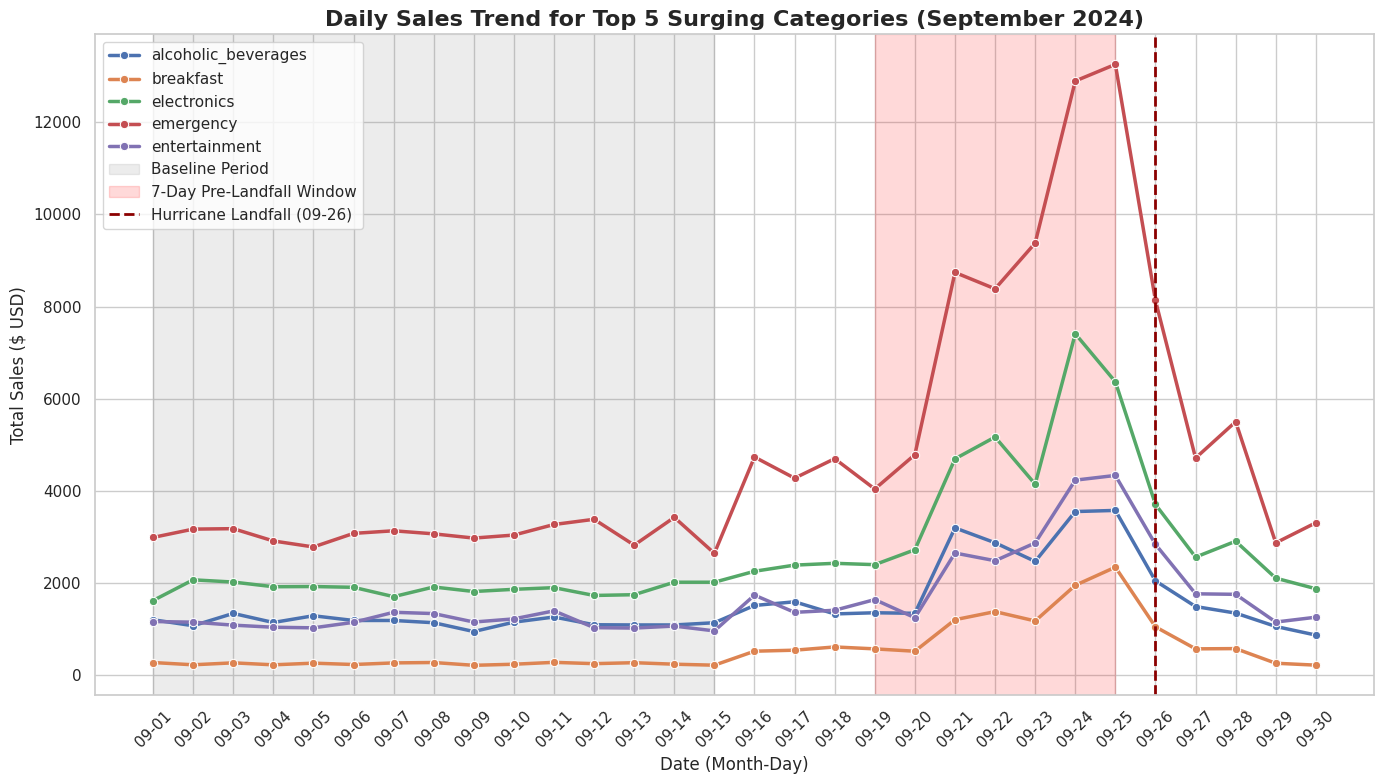

In [15]:
# 3. Plot the daily trend for the Top 5 Surging Categories
df_daily_cat = df_clean.groupby(['category', 'date'])['total_sales'].sum().reset_index()
df_daily_cat['date_str'] = df_daily_cat['date'].dt.strftime('%m-%d')

plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

# Filter for only top 5 categories
df_top5_daily = df_daily_cat[df_daily_cat['category'].isin(top_5_categories)].copy()

sns.lineplot(data=df_top5_daily, x='date_str', y='total_sales', hue='category', linewidth=2.5, marker='o')

# Highlight windows
plt.axvspan('09-01', '09-15', color='gray', alpha=0.15, label='Baseline Period')
plt.axvspan('09-19', '09-25', color='red', alpha=0.15, label='7-Day Pre-Landfall Window')
plt.axvline(x='09-26', color='darkred', linestyle='--', linewidth=2, label='Hurricane Landfall (09-26)')

plt.title('Daily Sales Trend for Top 5 Surging Categories (September 2024)', fontsize=16, fontweight='bold')
plt.xlabel('Date (Month-Day)', fontsize=12)
plt.ylabel('Total Sales ($ USD)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()


##QUESTION 1


Based on the transactions, we observed an intense spike around September 24-25 indicating that our hurricane landfall is around September 26th.

We defined our time periods as:


*   **Pre-Landfall Surge Window:** September 19, 2024 to September 25, 2024 ( 7 days prior to landfall)
*   **Baseline Window:** September 1, 2024 to September 15, 2024 ( normal historical baseline)

We compared the average daily sales revenue during these two time periods to determine which product categories experience the largest increases.

The top 5 product categories that we found were: Breafast, Emergency, Electronics, Entertainment and Alcoholic Beverages.

Breakfast had the largest increase of +415.4% with Emergency being the second-largest increase at +186.8%.

These results suggests that customers prepared for the hurricane through purchasing food, emergency supplies and products that would primarily be used while staying indoors.

The daily sales trend shows that purchasing started to increase around September 21st, as the hurricane was approaching and sales were at their highest levels about one or two days before landfall. Once, September 26 hit, sales declines, which could be due to store closures, evactation orders, or staying home due to the storm.




